# Devoir maison 2 — carnets J3 et J4

> **À rendre avant la séance 5** — comme tout devoir, avant la première séance de la semaine
> suivante. Ce devoir porte sur **J3** (comparer sans se mentir, puis ce qu’on fait des défauts
> trouvés) et sur **J4** (la mesure, et la révélation). Il se fait **seul**, à la maison, et il se
> rend.

**Ce qu’on rend :** ce carnet, rempli, déposé dans votre **dépôt GitHub personnel** avec la
déclaration d’usage de l’IA (`declaration_DM2.md`). **Le journal de nettoyage** et **le tableau à
quatre colonnes** en sont les pièces principales.

**Pourquoi ce devoir :** chaque question demande une mesure que **vous** produisez — pas une
lecture. Si vous n’avez pas compris, ça se verra tout de suite ; c’est fait pour ça.

**Ce qui est lu.** Ce qui est lu ici : **les tableaux** et le code. Les tableaux : le tableau à quatre colonnes, le
journal de nettoyage, vos métriques. Le code : là où il produit un chiffre. **Ce dépôt est
relevé** : il est lu. Les **sept devoirs** comptent ensemble pour **10 % de la
note**. C'est la composante « exercices et devoirs » du cours (25 %, avec E1, E2, E3).
**Il n’y a pas d’oral sur les devoirs** : l’oral individuel, en fin de parcours, porte sur
l’ensemble de votre travail.

**Trois mots, pour être sûr :**

- **la baseline** — le modèle bête qu’il faut battre : la réponse constante, ou la règle du délai en
  place. Un score ne se lit jamais seul.
- **la barre de bruit** — de combien un score bouge tout seul ; en dessous, un écart n’est pas un
  gain.
- **le coût et le seuil** — ce que le métier paie pour chaque erreur, et le niveau de probabilité
  au-delà duquel on alerte.

---

## Comment ça marche

1. La partie **« Mise en place »** est **fournie** : exécutez-la, ne la modifiez pas. C’est elle
   qui lit les données, construit la table, mesure les baselines, la matrice et le coût — sans
   elle, aucune question ne peut tourner.
2. Chaque **question** porte sa consigne, un squelette et des **contrôles de forme**. Ils
   vérifient la forme de votre réponse : un pourcentage, une dimension, une cohérence avec
   vos autres réponses). Ils ne donnent **jamais** la réponse, et ils se taisent tant que vous
   n’avez pas écrit.
3. Une réponse se **chiffre** ou s’**écrit** — jamais « ça a marché ». **Deux** questions demandent
   d’**annoncer ce que vous attendez avant de mesurer** : c’est volontaire.
4. **Votre échantillon personnel** : dans la mise en place, remplacez `MON_IDENTIFIANT` par votre
   pseudo GitHub. Deux questions (Q9, Q10) se calculent **sur votre échantillon** : sans cela, vos
   chiffres sont ceux de tout le monde, et votre copie se recopie d’un voisin.
5. **Cœur** et **approfondissement** se rendent dans le **même dépôt**. La
   différence ne porte pas sur la note : elle dit où porter votre effort.
6. À la fin : les **trois tableaux**, puis le **dépôt**.

> **Ce qui est évalué, et ce qui se lit.** Trois objets traversent tout le cours, et on vous
> interrogera dessus — en devoir, au partiel, à l’oral. Le premier est la fonction `predict` :
> l’interface que le professeur appelle sur une table brute. Le deuxième est le **tableau d’essais** :
> ce que vous avez annoncé, essayé, mesuré. Le troisième est le **journal de nettoyage** : chaque
> décision, son choix, son effet mesuré. Ce qu’ils **retournent** est ce qu’on vous demandera de
> défendre — et votre projet s’appuiera dessus.


## Mise en place (fournie)

Exécutez cette partie **de haut en bas**, sans rien y modifier. Elle reprend la chaîne des
carnets : les données, la table, les baselines et la barre, la matrice de confusion, le
coût métier.

Les `random_state=0` sont la **graine du tirage au sort** (expliquée en
J1 §5). Le même nombre redonne le même découpage, donc la même mesure.


### Les outils


In [1]:
# les outils
# Aucun import en bloc au début : chaque module entre dans le carnet au moment de son premier
# usage. On voit ainsi à quoi il sert, au lieu de le deviner dans une liste.

# `display` : un tableau s'affiche proprement dans un carnet, et reste lisible ailleurs.
# C'est par `display` qu'on montre TOUTES les tables de ce carnet — jamais un print de texte.
try:
    from IPython.display import display
except ImportError:
    def display(x):
        print(x)


### Les données


In [2]:
import os
import pandas as pd
# où sont les fichiers — on CHERCHE `train.csv`, on ne suppose pas un chemin
# (Kaggle a déjà déplacé ses points de montage : un chemin recopié se périme, une recherche non)
def _trouver_dossier(racines):
    """Première racine contenant train.csv — en surface, puis en profondeur."""
    for racine in racines:
        if not os.path.isdir(racine):
            continue
        if os.path.exists(os.path.join(racine, "train.csv")):
            return racine
        for chemin, _, fichiers in os.walk(racine):
            if "train.csv" in fichiers:
                return chemin
    return None

DOSSIER = _trouver_dossier(["/kaggle/input", "sortie"])
assert DOSSIER, "train.csv introuvable : les données de la compétition sont-elles montées ?"


In [3]:
train = pd.read_csv(os.path.join(DOSSIER, "train.csv"), low_memory=False)
test = pd.read_csv(os.path.join(DOSSIER, "test.csv"), low_memory=False)

ID, CIBLE = "ligne_id", "patient_absent"


### La table de travail


In [4]:
A_ECARTER = [ID, "dossier_id", "patient_id", "duree_consultation", "constantes_relevees",
             "motif_absence", "date_prise", "date_rdv", "taille_cm", "date_naissance",
             "canal_prise"]

def matrice(cols):
    """La table de travail : colonnes écartées retirées, catégorielles déclarées."""
    X = cols.drop(columns=[c for c in A_ECARTER + [CIBLE] if c in cols.columns]).copy()
    cat = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
    trop_fin = [c for c in cat if X[c].nunique() > 255]
    X = X.drop(columns=trop_fin)
    cat = [c for c in cat if c not in trop_fin]
    for c in cat:
        X[c] = X[c].fillna("").astype("category")
    return X, cat, trop_fin

X, CAT, TROP_FIN = matrice(train)
Xt, _, _ = matrice(test)

for c in CAT:
    Xt[c] = Xt[c].cat.set_categories(X[c].cat.categories)


### La cible, et la référence


In [5]:
repartition = pd.DataFrame({"lignes": [len(train), int(train[CIBLE].sum())],
                            "part (%)": [100.0, round(100 * train[CIBLE].mean(), 2)]},
                           index=["toutes", "absents"])

reference = 100 * max(train[CIBLE].mean(), 1 - train[CIBLE].mean())


In [6]:
# `y` entre ici ; la référence a déjà été calculée avec la distribution ci-dessus —
y = train[CIBLE]


### Le découpage, le modèle, et les baselines


In [7]:
# les baselines, sur le même jeu de validation — et la barre qui décide
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

Xtr, Xval, ytr, yval = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)

# 1) la réponse constante : le concurrent le plus bête, et le plus dur à battre
constante = 100 * max(yval.mean(), 1 - yval.mean())

# 2) la règle du délai : « j'annonce une absence si le délai dépasse N jours ».
#    N se choisit sur les lignes d'apprentissage, pas sur celles de contrôle.
delai_max = int(Xtr['delai_jours'].max())
taux_par_seuil = {s: float(((Xtr['delai_jours'] > s).astype(int) == ytr).mean())
                  for s in (0, 1, 3, 7, 14, 30) if s < delai_max}
seuil_appris = max(taux_par_seuil, key=taux_par_seuil.get)
regle = (Xval['delai_jours'] > seuil_appris).astype(int)

# et la règle qui ne dirait jamais rien ? c'est la réponse constante, au point près
silence = (Xval['delai_jours'] > delai_max).astype(int)

# 3) la famille linéaire : elle a besoin de nombres, on lui en prépare — la recette des
#    séances précédentes (newton-cholesky : le solveur qui converge sur cette table)
X_n = pd.get_dummies(X, columns=CAT).fillna(0)   # 0 = trou comblé ; le linéaire ne lit pas les NaN
Xtr_n, Xval_n = X_n.loc[Xtr.index], X_n.loc[Xval.index]
lineaire = LogisticRegression(solver='newton-cholesky').fit(Xtr_n, ytr)

# 4) le modèle du cours, celui des séances précédentes
modele = HistGradientBoostingClassifier(random_state=0).fit(Xtr, ytr)

# la barre : l'erreur-type de l'exactitude sur CE jeu de validation
barre = 100 * ((constante / 100) * (1 - constante / 100) / len(yval)) ** 0.5

baselines = pd.DataFrame([
    {'baseline': 'toujours présent',
     'exactitude (%)': round(constante, 2)},
    {'baseline': f'règle du délai — absent si le délai dépasse {seuil_appris} j',
     'exactitude (%)': round(100 * (regle == yval).mean(), 2)},
    {'baseline': 'absent si ce patient a déjà manqué un rendez-vous',
     'exactitude (%)': round(100 * ((Xval['taux_absence_passe'] > 0).astype(int) == yval).mean(), 2)},
    {'baseline': 'la famille linéaire',
     'exactitude (%)': round(100 * lineaire.score(Xval_n, yval), 2)},
    {'baseline': 'le modèle du cours',
     'exactitude (%)': round(100 * modele.score(Xval, yval), 2)},
])

ecart = 100 * modele.score(Xval, yval) - constante


### La matrice de confusion, et les probabilités


In [8]:
# les quatre cases, comptées à la main sur le jeu de contrôle
predit = modele.predict(Xval)

VP = int(((predit == 1) & (yval == 1)).sum())   # annoncé absent, et absent
FP = int(((predit == 1) & (yval == 0)).sum())   # annoncé absent, et venu : la fausse alerte
FN = int(((predit == 0) & (yval == 1)).sum())   # annoncé présent, et absent : l’absence manquée
VN = int(((predit == 0) & (yval == 0)).sum())   # annoncé présent, et venu

assert VP + FP + FN + VN == len(yval)

# et la probabilité, qui servira à déplacer le seuil : c’est elle qui décide, pas le 0/1
probabilites = modele.predict_proba(Xval)[:, 1]

# les quatre mêmes cases, retrouvées par la bibliothèque — le contrôle, pas la confiance
from sklearn.metrics import confusion_matrix
confirme = confusion_matrix(yval, predit).ravel()          # ordre : VN, FP, FN, VP
assert (VN, FP, FN, VP) == tuple(int(v) for v in confirme), 'les quatre cases ne concordent pas'


### Le coût métier


In [9]:
# le coût d’une décision, et la dérivation du seuil
COUT_FP, COUT_FN = 25, 100   # les deux montants de l’énoncé, en unités de coût

def cout(decision, verite=yval):
    faux_positifs = int(((decision == 1) & (verite == 0)).sum())
    faux_negatifs = int(((decision == 0) & (verite == 1)).sum())
    return COUT_FP * faux_positifs + COUT_FN * faux_negatifs

seuil_theorique = COUT_FP / (COUT_FP + COUT_FN)


### Les outils du nettoyage


In [10]:
# un trou aléatoire : cinq traitements, et ce que chacun change
def score_de(Xe, ye=None):
    """Entraîne et mesure, toujours sur la même découpe."""
    ye = y if ye is None else ye
    Xtr_m, Xval_m, ytr_m, yval_m = train_test_split(Xe, ye, test_size=0.2, stratify=ye, random_state=0)
    return 100 * HistGradientBoostingClassifier(random_state=0).fit(Xtr_m, ytr_m).score(Xval_m, yval_m)

# le même découpage, les lignes retirées seulement côté apprentissage : le jeu de contrôle
# ne change pas, donc les deux scores se comparent vraiment — ce que `score_de` ne fait pas
def score_sans_lignes(masque):
    """Retire des lignes du seul côté apprentissage, et mesure sur le même jeu de contrôle."""
    garde = masque.loc[Xtr.index]
    return 100 * HistGradientBoostingClassifier(random_state=0).fit(
        Xtr[garde], ytr[garde]).score(Xval, yval)


In [11]:
# les colonnes inutiles, et la raison de chacune
raisons = {
    "zone_clinique": "une seule valeur sur toute la table",
    "indice_meteo_jour": "du bruit pur",
    "score_territorial": "42 052 valeurs, aucune raison de croire qu’elles disent quelque chose",
    "age_mois": "age_mois ÷ 12 = age — sur 100 % des lignes (mesuré en J1, 2.6)",
    "cout_acte": "montant_acte = 13,68 × cout_acte, rapport constant (mesuré en J1, 2.6)",
}
inutiles = [c for c in raisons if c in X.columns]


In [12]:
# le journal de nettoyage — ce qui est lu n’est pas le score, c’est le tableau
JOURNAL = []

def journal(decision, choix, raison, effet):
    """Une décision, le choix fait, la raison qu’on donnerait à un audit, et l’effet mesuré
       en points — avec la comparaison au double de la barre, qui dit si l’effet compte."""
    JOURNAL.append({"décision": decision, "choix": choix, "raison (sans le score)": raison,
                    "effet mesuré": round(effet, 2),
                    "> double de la barre ?": "oui" if abs(effet) > 2 * barre else "non"})
    display(pd.DataFrame(JOURNAL))


### Le pipeline, et le fichier à envoyer


In [13]:
# le pipeline : de la table brute à la prédiction, en un seul endroit
# Même contrat que `predict` : une table brute entre, un 0/1 par ligne sort.
def nettoyer(brut):
    """Les décisions apprises sur la table d’apprentissage, appliquées à une table brute :
       colonnes inutiles écartées, colonnes trop fines écartées, et les catégories de
       l’apprentissage — jamais recalculées sur la table qu’on reçoit."""
    d = matrice(brut)[0]
    d = d.drop(columns=[c for c in inutiles if c in d.columns])
    d = d[[c for c in X.columns if c in d.columns]]
    for c in CAT:
        if c not in d.columns:
            continue
        d[c] = d[c].astype("category").cat.set_categories(X[c].cat.categories)
    return d

def pipeline(brut):
    """Reçoit une table brute et rend un tableau de 0/1 — la chaîne complète."""
    return modele_final.predict(nettoyer(brut)).astype(int)

X_propre = nettoyer(train)
modele_final = HistGradientBoostingClassifier(random_state=0).fit(X_propre, y)

soumission = pd.DataFrame({ID: test[ID], CIBLE: pipeline(test)})
soumission.to_csv("submission.csv", index=False)


### Le rituel : annoncer avant de mesurer


In [14]:
# l'horloge entre ici : c'est elle qui rend une prédiction vérifiable
from datetime import datetime

ESSAIS = []
PREDICTIONS = []

def prevoir(essai, attendu, raison):
    """Écrit ce que vous attendez AVANT de mesurer — horodaté.
       `noter(...)` refuse ensuite tout essai sans prédiction : l'ordre n'est pas demandé, il est
       appliqué. Ce que cette fonction garantit, exactement : une prédiction EXISTAIT avant que la
       ligne du tableau soit écrite. Elle ne date pas la mesure — le score lui arrive déjà calculé.
       Pour la garantie complète, mesurez dans `essai(...)`, qui date la mesure lui-même."""
    PREDICTIONS[:] = [p for p in PREDICTIONS if p["essai"] != essai]
    PREDICTIONS.append({"essai": essai, "attendu": attendu, "raison": raison,
                        "écrit à": datetime.now().strftime("%H:%M:%S")})
    display(pd.DataFrame(PREDICTIONS))

def essai(nom, mesure, changement="", attendu=""):
    """Le chemin STRICT : la mesure est prise ICI, donc l'ordre (prédiction puis mesure) est prouvé.
       `mesure` est une fonction sans argument qui rend le score, par exemple
       `lambda: modele.score(Xval, yval)`. Refuse de mesurer sans prédiction."""
    prevu = [p for p in PREDICTIONS if p["essai"] == nom]
    if not prevu:
        print(f"refusé : aucune prédiction pour « {nom} ». Écrivez prevoir(...) d'abord.")
        return None
    score = 100 * mesure()
    noter(nom, changement or "voir la question", attendu or prevu[0]["attendu"], score)
    return score

def noter(hypothese, changement, attendu, score):
    """Ajoute une ligne au tableau. `attendu` : un signe et une raison, jamais une valeur.
       Ré-exécuter une cellule REMPLACE la ligne de même `hypothèse` : elle ne la double pas.

       REFUSE d'enregistrer un essai non annoncé — c'est la règle du cours, appliquée.
       Ce qu'elle garantit, et rien de plus : une prédiction existait AVANT que cette ligne soit
       écrite. Elle ne date pas la mesure — d'où `essai(...)` pour la garantie complète."""
    prevu = [p for p in PREDICTIONS if p["essai"] == hypothese]
    if not prevu:
        print(f"  refusé : aucune prédiction pour « {hypothese} ».")
        print("  Écrivez prevoir(...) d'abord — l'ordre est vérifié, pas seulement demandé.")
        return
    ligne = {"hypothèse": hypothese, "changement": changement,
             "attendu": attendu, "mesuré": round(score, 2),
             "prédiction écrite avant ?": "oui, à " + prevu[0]["écrit à"]}
    ESSAIS[:] = [e for e in ESSAIS if e["hypothèse"] != hypothese] + [ligne]
    display(pd.DataFrame(ESSAIS))


### Votre échantillon personnel — **à personnaliser**

Deux questions se calculent sur un **échantillon qui n’appartient qu’à vous** : il est tiré de
votre identifiant. Il fait la moitié du jeu de contrôle. Remplacez la ligne `MON_IDENTIFIANT`
par votre pseudo GitHub, puis exécutez la cellule : elle affiche la taille de votre échantillon et
sa graine. Le reste de la mise en place, lui, ne se modifie pas.


In [15]:
# ── votre échantillon personnel : il ne change que les chiffres que vous devez produire
import zlib

MON_IDENTIFIANT = "remplacez-par-votre-pseudo-github"   # ← en minuscules, sans espace
graine_perso = zlib.crc32(MON_IDENTIFIANT.strip().lower().encode())
positions = Xval.sample(frac=0.5, random_state=graine_perso).index
ou = Xval.index.get_indexer(positions)
Xval_perso, yval_perso, proba_perso = Xval.loc[positions], yval.loc[positions], probabilites[ou]

print(f"votre échantillon personnel : {len(positions)} lignes (la moitié du jeu de contrôle), graine {graine_perso}")
if "remplacez" in MON_IDENTIFIANT:
    print("  ⚠ remplacez MON_IDENTIFIANT par votre pseudo : sinon votre échantillon est celui de tout le monde.")


votre échantillon personnel : 14990 lignes (la moitié du jeu de contrôle), graine 1463641752
  ⚠ remplacez MON_IDENTIFIANT par votre pseudo : sinon votre échantillon est celui de tout le monde.


### Les vérifications, et le tableau d’essais


In [16]:
def phrases(reponse):
    """Une réponse de prose peut arriver en liste, en Series ou en table : on la ramène à des phrases."""
    if hasattr(reponse, "to_dict"):
        return [str(v) for ligne in reponse.to_dict("records") for v in ligne.values()]
    return [str(p) for p in reponse]

VERIFICATIONS = []

def verifier(nom, condition, indice=''):
    """Contrôle silencieux : il ne dit jamais la valeur attendue."""
    VERIFICATIONS.append({'contrôle': nom, 'tient': bool(condition)})
    print(('  ok        ' if condition else '  À REVOIR  ') + nom
          + ('' if condition else '   ->   ' + indice))

def controle(nom, quoi, indice=''):
    """Contrôle de forme, posé dans la cellule de la question. Il ne compare jamais à une valeur
       attendue : un type, une plage, une dimension, ou une cohérence avec vos autres réponses.
       Tant que la réponse n’est pas écrite, il se tait."""
    try:
        ok = bool(quoi())
    except NameError:
        print(f'  (pas encore écrit)  {nom}')
        return
    except Exception as e:
        print(f'  REVOIR    {nom}   ->   {type(e).__name__} : {e}')
        return
    VERIFICATIONS.append({'contrôle': nom, 'tient': ok})
    print(('  ok        ' if ok else '  REVOIR    ') + nom + ('' if ok else '   ->   ' + indice))

# le tableau d'essais et son `noter` strict viennent de la mise en place (extraits de J1) :
# il refuse un essai non annoncé. Le devoir n'en redéfinit pas un second, plus permissif.


### La mise en place est-elle prête ?


In [17]:
# sept vérifications d'état — elles portent sur la mise en place, pas sur vos réponses
verifier('les données sont chargées', len(train) > 100_000)
verifier('la table de travail est construite', 'patient_absent' not in X.columns)
verifier('le découpage est fait, le modèle ajusté', len(probabilites) == len(yval))
verifier('les baselines sont mesurées', constante > 50 and barre > 0)
verifier('votre échantillon personnel est prêt', len(yval_perso) > 1000)
verifier('le pipeline tourne sur une table brute', len(pipeline(test.head(50))) == 50)
verifier('le fichier est écrit', os.path.exists('submission.csv'))


  ok        les données sont chargées
  ok        la table de travail est construite
  ok        le découpage est fait, le modèle ajusté
  ok        les baselines sont mesurées
  ok        votre échantillon personnel est prêt
  ok        le pipeline tourne sur une table brute
  ok        le fichier est écrit


## Les questions

**Douze questions : dix de cœur, deux d’approfondissement.** Elles suivent l’ordre des
carnets — J3 d’abord (comparer, puis nettoyer), J4 ensuite (la mesure). Pour chacune : lisez
la consigne, écrivez votre code (ou votre phrase) à l’emplacement prévu, et **exécutez la
cellule** — c’est l’exécution qui déclenche les contrôles.


### Question 1 — Une baseline de votre main, et sa place dans le tableau  ·  *carnet J3*  ·  *cœur*


**Contexte.** Le carnet J3 a mesuré **ses** baselines. La vôtre doit être la vôtre.

**Consigne.**
  1. choisissez une colonne que **ni la réponse constante ni la règle du délai du carnet**
     (`delai_jours`) n'utilise. Écrivez la règle en une phrase : quel signal, quelle décision ;
  2. mesurez son exactitude sur le jeu de validation (`Xval`, `yval`) ;
  3. divisez son écart à `constante` — la réponse constante, **81,75 %** — par `barre` : combien
     d'erreurs-types cela fait-il ?

**Livrables.** `ma_regle` · `ma_baseline` · `mes_erreurs_types`.

**Critère de réussite.** Une règle qui **égale ou dépasse** la constante est un résultat — dites-le.
Un écart sous une barre n'est pas un gain.

*≈ 20 min.*


In [18]:


ages_a_tester = [10, 20, 30, 40, 50]

# 1) Tester les règles sur le jeu d'apprentissage
resultats = []

for a in ages_a_tester:
    plus_grand = (Xtr["age"] > a).astype(int)
    plus_petit = (Xtr["age"] < a).astype(int)

    resultats.append(((plus_grand == ytr).mean(), "plus grand", a))
    resultats.append(((plus_petit == ytr).mean(), "plus petit", a))

# 2) Choisir la règle la plus précise sur l'apprentissage
meilleur_score, sens, age_choisi = max(resultats, key=lambda r: r[0])

# 3) Évaluer cette règle sur la validation
if sens == "plus petit":
    ma_pred = (Xval["age"] < age_choisi).astype(int)
else:
    ma_pred = (Xval["age"] > age_choisi).astype(int)

ma_baseline = 100 * (ma_pred == yval).mean()

# 4) Calculer l'écart à la réponse constante en erreurs-types
mes_erreurs_types = (ma_baseline - constante) / barre

# 5) Décrire la règle en une phrase
ma_regle = (
    f"Si l'âge est {sens} que {age_choisi} ans, "
    "je prédis une absence ; sinon, je prédis une présence."
)

# 6) Afficher les trois livrables
print("ma_regle =", ma_regle)
print(f"ma_baseline = {ma_baseline:.2f} %")
print(f"Réponse constante = {constante:.2f} %")
print(f"mes_erreurs_types = {mes_erreurs_types:.2f}")

# Interpréter le résultat
if ma_baseline >= constante:
    print("Résultat : la règle égale ou dépasse la référence constante.")
else:
    print("Résultat : la règle est moins précise que la référence constante.")

if abs(mes_erreurs_types) < 1:
    print("L'écart est inférieur à une erreur-type : ce n'est pas un gain net.")

controle('la règle est écrite', lambda: len(ma_regle) > 40,
         'décrivez la colonne et la décision en une phrase')
controle('une exactitude en pourcentage', lambda: 0 < ma_baseline <= 100,
         'un pourcentage (0 à 100), pas une proportion')
controle('un écart exprimé en erreurs-types', lambda: 0 <= abs(mes_erreurs_types) < 30,
         'divisez votre écart par la barre')


ma_regle = Si l'âge est plus petit que 10 ans, je prédis une absence ; sinon, je prédis une présence.
ma_baseline = 79.81 %
Réponse constante = 81.75 %
mes_erreurs_types = -8.70
Résultat : la règle est moins précise que la référence constante.
  ok        la règle est écrite
  ok        une exactitude en pourcentage
  ok        un écart exprimé en erreurs-types


In [19]:
print("Variables disponibles :")
for nom in ["X", "y", "Xtr", "ytr", "Xval", "yval",
            "X_train", "y_train", "X_test", "y_test"]:
    print(nom, ":", nom in globals())


Variables disponibles :
X : True
y : True
Xtr : True
ytr : True
Xval : True
yval : True
X_train : False
y_train : False
X_test : False
y_test : False


### Question 2 — Le classement affiché tient-il ?  ·  *carnet J3*  ·  *cœur*


**Contexte.** En J3, douze variantes jugées sur 1 000 lignes affichées ne se retrouvaient pas sur
celles jamais montrées. L'**affichage** est l'échantillon sur lequel le classement se lit ; le reste, celui qu'on
ne regarde pas avant de mesurer.

**Consigne.**
  1. annoncez **avant** de mesurer : le premier de l’affichage sera-t-il aussi le premier des lignes jamais montrées ?
  2. pour cette question, mettez **4 000 lignes de côté dans `Xtr`, avant d’entraîner** : elles ne servent ni à
     l’apprentissage, ni au choix des réglages. Coupez-les en 1 000 pour l’affichage et 3 000 jamais
     montrées (`train_test_split`, `random_state=0`) ;
  3. faites varier **six** réglages de votre choix, chacun entraîné sur les lignes qui restent — et dites **ce qui varie** (le nombre
     d'itérations ? la profondeur ? les deux ?) ;
  4. mesurez. Le premier de l’affichage est la variante qui a le meilleur score sur les 1 000.
     Donnez son **rang** parmi les lignes jamais montrées (1 = premier).

**Livrables.** `mon_annonce` · `score_affiche_premier` · `score_jamais_montre_premier` · `rang_jamais_montre_premier`.

**Critère de réussite.** Un seul tirage ne prouve pas qu'« un classement tient » : il montre **ce**
tirage-là. Dites ce que vous pouvez conclure, et ce que vous ne pouvez pas.

*≈ 25 min.*


In [20]:






# AVANT de mesurer : écrire sa propre phrase
mon_annonce = (
    "Je pense que le premier modèle sur les données affichées ne sera "
    "pas forcément le premier sur les données jamais montrées, car "
    "ses performances peuvent varier selon les données évaluées."
)

# 1) Mettre 4000 lignes de côté avant l'entraînement
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
import pandas as pd

Xtr_reste, X_cote, ytr_reste, y_cote = train_test_split(
    Xtr, ytr,
    test_size=4000,
    random_state=0,
    stratify=ytr
)

# 2) Séparer les 4000 lignes :
# 1000 pour l'affichage et 3000 jamais montrées
X_aff, X_jam, y_aff, y_jam = train_test_split(
    X_cote, y_cote,
    test_size=3000,
    random_state=0,
    stratify=y_cote
)

# 3) Tester six réglages
reglages = [
    (20, 3),
    (50, 3),
    (100, 3),
    (50, 6),
    (100, 6),
    (200, 6)
]

resultats_q2 = []

for nb_arbres, profondeur in reglages:
    modele = HistGradientBoostingClassifier(
        max_iter=nb_arbres,
        max_depth=profondeur,
        early_stopping=False,
        random_state=0
    )

    modele.fit(Xtr_reste, ytr_reste)

    score_aff = 100 * modele.score(X_aff, y_aff)
    score_jam = 100 * modele.score(X_jam, y_jam)

    resultats_q2.append(
        (nb_arbres, profondeur, score_aff, score_jam)
    )

# 4) Construire le tableau des résultats
tab = pd.DataFrame(
    resultats_q2,
    columns=[
        "max_iter",
        "max_depth",
        "affichage (%)",
        "jamais montrées (%)"
    ]
)

tab["rang jamais montrées"] = (
    tab["jamais montrées (%)"]
    .rank(ascending=False, method="min")
    .astype(int)
)

display(tab)

# 5) Identifier le premier modèle sur l'affichage
premier = tab["affichage (%)"].idxmax()

score_affiche_premier = tab.loc[premier, "affichage (%)"]
score_jamais_montre_premier = tab.loc[premier, "jamais montrées (%)"]
rang_jamais_montre_premier = int(
    tab.loc[premier, "rang jamais montrées"]
)

print("Mon annonce :", mon_annonce)
print("Premier de l'affichage :", round(score_affiche_premier, 2), "%")
print(
    "Score sur les lignes jamais montrées :",
    round(score_jamais_montre_premier, 2), "%"
)
print(
    "Rang sur les lignes jamais montrées :",
    rang_jamais_montre_premier,
    "sur 6"
)

controle('une annonce est écrite avant la mesure', lambda: len(mon_annonce) > 30,
         'annoncez ce que vous attendez, en une phrase')
controle('deux scores en pourcentage',
         lambda: 50 < score_affiche_premier <= 100 and 50 < score_jamais_montre_premier <= 100,
         'deux pourcentages, un par jeu')
controle('un rang entre 1 et 6', lambda: 1 <= rang_jamais_montre_premier <= 6,
         'votre premier de l’affichage est l’un de vos six : donnez son rang parmi les lignes jamais montrées')


,max_iter,max_depth,affichage (%),jamais montrées (%),rang jamais montrées
0,20,3,83.2,82.800000,2
1,50,3,83.0,82.633333,4
2,100,3,82.9,82.866667,1
3,50,6,82.9,82.533333,5
4,100,6,82.5,82.666667,3
5,200,6,82.5,82.266667,6


Mon annonce : Je pense que le premier modèle sur les données affichées ne sera pas forcément le premier sur les données jamais montrées, car ses performances peuvent varier selon les données évaluées.
Premier de l'affichage : 83.2 %
Score sur les lignes jamais montrées : 82.8 %
Rang sur les lignes jamais montrées : 2 sur 6
  ok        une annonce est écrite avant la mesure
  ok        deux scores en pourcentage
  ok        un rang entre 1 et 6


### Question 3 — Deux modèles, un seul découpage  ·  *carnet J3*  ·  *cœur*


**Contexte.** En J3, deux réglages comparés sur le même découpage différaient de **0,04 point**.

**Consigne.**
  1. entraînez **deux modèles de votre choix** sur `Xtr` — deux familles, ou deux réglages
     réellement différents. Attention : deux `max_iter` du même modèle boosté peuvent s'arrêter au
     **même arbre** (l'arrêt anticipé) et comparer un modèle à lui-même ;
  2. mesurez-les sur **le même** `Xval` ;
  3. écrivez l'écart en points, et dites s'il fait plus qu'**une** barre de bruit, plus que **deux**.

**Livrables.** `score_a` · `score_b` · `mon_verdict`.

**Critère de réussite.** La comparaison n'est honnête que si le découpage ne change pas entre les
deux mesures. Dites aussi, en une phrase, si les deux modèles sont vraiment deux modèles.

*≈ 20 min.*


In [21]:


from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Modèle A : régression logistique
modele_a = LogisticRegression(solver="newton-cholesky")
modele_a.fit(Xtr_n, ytr)

score_a = 100 * modele_a.score(Xval_n, yval)

# Modèle B : forêt aléatoire
modele_b = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    random_state=0,
    n_jobs=-1
)
modele_b.fit(Xtr_n, ytr)

score_b = 100 * modele_b.score(Xval_n, yval)

# Calcul de l'écart entre les deux modèles
ecart = abs(score_a - score_b)
nb_barres = ecart / barre

print("Score A (logistique) :", round(score_a, 2), "%")
print("Score B (forêt)      :", round(score_b, 2), "%")
print("Écart :", round(ecart, 2), "points")
print("Nombre de barres :", round(nb_barres, 2))

# Verdict selon le nombre de barres
if nb_barres > 2:
    avis = (
        "L'écart dépasse deux barres de bruit : "
        "il est important selon ce critère."
    )
elif nb_barres > 1:
    avis = (
        "L'écart dépasse une barre, mais pas deux : "
        "le résultat reste incertain."
    )
else:
    avis = (
        "L'écart est inférieur ou égal à une barre de bruit : "
        "on ne peut pas affirmer qu'un modèle est meilleur."
    )

mon_verdict = (
    f"Les deux modèles sont évalués sur le même jeu de validation. "
    f"L'écart est de {ecart:.2f} points, soit {nb_barres:.2f} barres. "
    f"{avis} Les modèles comparés sont une régression logistique "
    f"et une forêt aléatoire."
)

print("\nMon verdict :")
print(mon_verdict)

controle('deux scores en pourcentage',
         lambda: 50 < score_a <= 100 and 50 < score_b <= 100, 'deux pourcentages')
controle('un verdict écrit', lambda: len(mon_verdict) > 40,
         'dites si l’écart dépasse une barre, deux barres, ou aucune')


Score A (logistique) : 82.21 %
Score B (forêt)      : 81.84 %
Écart : 0.36 points
Nombre de barres : 1.63

Mon verdict :
Les deux modèles sont évalués sur le même jeu de validation. L'écart est de 0.36 points, soit 1.63 barres. L'écart dépasse une barre, mais pas deux : le résultat reste incertain. Les modèles comparés sont une régression logistique et une forêt aléatoire.
  ok        deux scores en pourcentage
  ok        un verdict écrit


### Question 4 — Votre tableau à quatre colonnes  ·  *carnet J3*  ·  *cœur*


**Contexte.** Le tableau à quatre colonnes du carnet J3, rempli avec **vos** lignes.

**Consigne.**
  1. construisez `mon_tableau` avec les quatre colonnes du carnet — `modèle · validation · affiché ·
     écart` — et **au moins deux** lignes de votre choix ;
  2. la colonne de l’**affichage** ne se remplit que pour un modèle **réellement envoyé**. Aucun
     envoi n’est demandé ici : reprenez le score affiché du cours (**81,81**) sur la ligne du
     modèle du cours, et laissez `None` ailleurs ;
  3. écrivez les trois phrases : *que ferais-je si je ne regardais que l’affichage ? qu'est-ce que
     cela me coûterait en vrai ? qu'est-ce qui me l'aurait dit ?*

**Livrables.** `mon_tableau` · `si_je_ne_voyais_que_l_affichage` · `ce_que_cela_couterait` ·
`ce_qui_me_l_aurait_dit`.

**Critère de réussite.** Une colonne vide n'est pas un oubli — c'est un modèle qui n'a pas été
envoyé. Un écart sain est petit ; un écart qui grandit dit que le modèle a été choisi pour plaire à l’affichage.

*≈ 20 min.*


In [22]:

import pandas as pd

# Modèle du cours : validation et score affiché
val_cours = 100 * modele.score(Xval, yval)
affiche_cours = 81.81

# Tableau comparatif des trois modèles
mon_tableau = pd.DataFrame([
    {
        "modèle": "modèle du cours (boosting)",
        "validation": round(val_cours, 2),
        "affiché": affiche_cours,
        "écart": round(affiche_cours - val_cours, 2)
    },
    {
        "modèle": "régression logistique",
        "validation": round(score_a, 2),
        "affiché": None,
        "écart": None
    },
    {
        "modèle": "forêt aléatoire",
        "validation": round(score_b, 2),
        "affiché": None,
        "écart": None
    }
])

display(mon_tableau)

# Phrase 1 : ce que je choisirais en regardant uniquement l'affichage
si_je_ne_voyais_que_l_affichage = (
    "Si je ne regardais que le score affiché, je choisirais le modèle "
    "qui semble le meilleur, sans savoir s'il sera aussi performant "
    "sur des données qu'il n'a jamais vues."
)

# Phrase 2 : les conséquences possibles
ce_que_cela_couterait = (
    "Je pourrais choisir un modèle moins performant sur les nouvelles données, "
    "ce qui entraînerait davantage d'erreurs dans les prédictions d'absence."
)

# Phrase 3 : comment le tableau peut aider
ce_qui_me_l_aurait_dit = (
    "Le tableau permet de comparer le score affiché au score de validation. "
    "Un écart important peut signaler que le score affiché représente mal "
    "les performances sur les données de validation."
)

print("\n1. Si je ne voyais que l'affichage :")
print(si_je_ne_voyais_que_l_affichage)

print("\n2. Ce que cela pourrait me coûter :")
print(ce_que_cela_couterait)

print("\n3. Ce qui me l'aurait indiqué :")
print(ce_qui_me_l_aurait_dit)


controle('un tableau d’au moins deux modèles',
         lambda: len(mon_tableau) >= 2, 'deux lignes au moins')
controle('les trois phrases sont écrites',
         lambda: min(len(si_je_ne_voyais_que_l_affichage),
                     len(ce_que_cela_couterait), len(ce_qui_me_l_aurait_dit)) > 40,
         'trois phrases, chacune complète')


,modèle,validation,affiché,écart
0,modèle du cours (boosting),82.34,81.81,-0.53
1,régression logistique,82.21,NaN,NaN
2,forêt aléatoire,81.84,NaN,NaN



1. Si je ne voyais que l'affichage :
Si je ne regardais que le score affiché, je choisirais le modèle qui semble le meilleur, sans savoir s'il sera aussi performant sur des données qu'il n'a jamais vues.

2. Ce que cela pourrait me coûter :
Je pourrais choisir un modèle moins performant sur les nouvelles données, ce qui entraînerait davantage d'erreurs dans les prédictions d'absence.

3. Ce qui me l'aurait indiqué :
Le tableau permet de comparer le score affiché au score de validation. Un écart important peut signaler que le score affiché représente mal les performances sur les données de validation.
  ok        un tableau d’au moins deux modèles
  ok        les trois phrases sont écrites


### Question 5 — Le plafond : trois familles  ·  *carnet J3*  ·  *cœur*


**Contexte.** Trois familles qui ne partagent pas leur mécanisme plafonnent au même endroit : le
plafond n'est alors pas dans le modèle.

**Consigne.**
  1. annoncez **avant** : trois familles très différentes donneront-elles des scores très
     différents ?
  2. mesurez **trois familles **différentes** de votre choix** sur la même table, et le même découpage ;
  3. dites de combien de points la meilleure dépasse la moins bonne. Puis ce que cela implique :
     le plafond est-il dans le modèle, ou dans les données — **en exactitude** ?

**Livrables.** `mon_annonce_plafond` · `trois_scores` · `ma_conclusion_plafond`.

**Critère de réussite.** Toute conclusion doit venir avec l'écart **chiffré** entre la meilleure et la moins bonne — sinon c'est une impression.

*≈ 15 min.*


In [23]:


from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Avant de mesurer : écrire sa propre prédiction
mon_annonce_plafond = (
    "Je pense que les trois familles peuvent obtenir des scores proches, "
    "mais que leurs résultats peuvent différer selon leur manière "
    "d'apprendre les données."
)

# Modèle 1 : régression logistique
modele_logistique = LogisticRegression(solver="newton-cholesky")
modele_logistique.fit(Xtr_n, ytr)
score_logistique = 100 * modele_logistique.score(Xval_n, yval)

# Modèle 2 : forêt aléatoire
modele_foret = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    random_state=0,
    n_jobs=-1
)
modele_foret.fit(Xtr_n, ytr)
score_foret = 100 * modele_foret.score(Xval_n, yval)

# Modèle 3 : boosting du cours
score_boosting = 100 * modele.score(Xval, yval)

# Comparaison des trois scores
trois_scores = [
    round(score_logistique, 2),
    round(score_foret, 2),
    round(score_boosting, 2)
]

ecart_q5 = max(trois_scores) - min(trois_scores)

print("Mon annonce :", mon_annonce_plafond)
print("Régression logistique :", trois_scores[0], "%")
print("Forêt aléatoire       :", trois_scores[1], "%")
print("Boosting              :", trois_scores[2], "%")
print("Écart entre le meilleur et le moins bon :",
      round(ecart_q5, 2), "points")

# Comparaison avec la barre de bruit calculée précédemment
nb_barres_q5 = ecart_q5 / barre

print("Écart en barres de bruit :", round(nb_barres_q5, 2))

if nb_barres_q5 < 2:
    avis_q5 = (
        "Les scores sont relativement proches selon le seuil choisi. "
        "Cela ne prouve toutefois pas que les données constituent "
        "la seule limite des modèles."
    )
else:
    avis_q5 = (
        "Les scores présentent un écart important selon le seuil choisi. "
        "Le choix du modèle peut encore avoir une influence."
    )

ma_conclusion_plafond = (
    f"La meilleure famille dépasse la moins bonne de {ecart_q5:.2f} points, "
    f"soit {nb_barres_q5:.2f} barres de bruit. {avis_q5}"
)

print("\nMa conclusion :")
print(ma_conclusion_plafond)

controle('une annonce est écrite avant la mesure', lambda: len(mon_annonce_plafond) > 30,
         'annoncez l’écart attendu entre trois familles')
controle('trois scores', lambda: len(trois_scores) == 3, 'trois familles, trois scores')
controle('la conclusion est argumentée', lambda: len(str(ma_conclusion_plafond)) > 40,
         'dites si le plafond est dans le modèle ou dans les données')


Mon annonce : Je pense que les trois familles peuvent obtenir des scores proches, mais que leurs résultats peuvent différer selon leur manière d'apprendre les données.
Régression logistique : 82.21 %
Forêt aléatoire       : 81.84 %
Boosting              : 82.34 %
Écart entre le meilleur et le moins bon : 0.5 points
Écart en barres de bruit : 2.24

Ma conclusion :
La meilleure famille dépasse la moins bonne de 0.50 points, soit 2.24 barres de bruit. Les scores présentent un écart important selon le seuil choisi. Le choix du modèle peut encore avoir une influence.
  ok        une annonce est écrite avant la mesure
  ok        trois scores
  ok        la conclusion est argumentée


### Question 6 — Le bruit d’étiquette  ·  *carnet J3*  ·  *cœur*


**Contexte.** Le plafond peut aussi venir des **étiquettes** : personne n'annote parfaitement, et un
annotateur ne se trompe pas comme un modèle.

**Consigne.**
  1. retournez **15 %** des étiquettes d’**entraînement** (`ytr`), au hasard (`random_state=0`),
     et gardez **deux** modèles de la question 5 ;
  2. mesurez sur une validation **intacte** (`Xval`, `yval`) — sinon on mesure le bruit, pas ce
     qu'il coûte ;
  3. comparez chaque score à son score propre de la question 5, puis dites **quel** modèle est le
     plus abîmé, et de combien de points. Dites enfin ce que cela implique pour la **fiabilité des
     étiquettes** de ce jeu.

**Livrables.** `scores_bruites` · `modele_le_plus_abime` · `ma_conclusion_cible`.

**Critère de réussite.** Ce n'est pas « le score baisse-t-il ? » qui compte, mais **sur quel modèle** le
bruit mord — et pourquoi il est le plus touché.

*≈ 15 min.*


In [24]:


import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

# 1) Retourner exactement 15 % des étiquettes d'apprentissage au hasard
rng = np.random.RandomState(0)

n_a_retourner = int(0.15 * len(ytr))

positions_a_retourner = rng.choice(
    len(ytr),
    size=n_a_retourner,
    replace=False
)

valeurs = ytr.to_numpy().copy()
valeurs[positions_a_retourner] = 1 - valeurs[positions_a_retourner]

ytr_bruite = pd.Series(valeurs, index=ytr.index)

print("Étiquettes retournées :", n_a_retourner, "sur", len(ytr))

# 2) Réentraîner les deux modèles avec les étiquettes modifiées

log_bruitee = LogisticRegression(
    solver="newton-cholesky"
).fit(Xtr_n, ytr_bruite)

boost_bruite = HistGradientBoostingClassifier(
    random_state=0
).fit(Xtr, ytr_bruite)

# 3) Évaluer les modèles sur la validation intacte

score_log_bruite = 100 * log_bruitee.score(Xval_n, yval)
score_boost_bruite = 100 * boost_bruite.score(Xval, yval)

print("\nRésultats avec les étiquettes modifiées :")
print("Logistique :", round(score_log_bruite, 2), "%")
print("Boosting   :", round(score_boost_bruite, 2), "%")

# 4) Comparer aux scores propres de la Q5

perte_log = score_logistique - score_log_bruite
perte_boost = score_boosting - score_boost_bruite

print("\nComparaison avec la Q5 :")

print(
    "Logistique : propre",
    round(score_logistique, 2),
    "% → bruité",
    round(score_log_bruite, 2),
    "% (perte de",
    round(perte_log, 2),
    "points)"
)

print(
    "Boosting : propre",
    round(score_boosting, 2),
    "% → bruité",
    round(score_boost_bruite, 2),
    "% (perte de",
    round(perte_boost, 2),
    "points)"
)

# 5) Identifier le modèle qui perd le plus de points

if perte_boost > perte_log:
    modele_le_plus_abime = (
        f"le boosting, qui perd {perte_boost:.2f} points "
        f"contre {perte_log:.2f} points pour la logistique"
    )
else:
    modele_le_plus_abime = (
        f"la logistique, qui perd {perte_log:.2f} points "
        f"contre {perte_boost:.2f} points pour le boosting"
    )

ma_conclusion_cible = (
    f"Le modèle le plus affecté est {modele_le_plus_abime}. "
    "La comparaison indique dans quelle mesure les performances "
    "de chaque modèle diminuent lorsque 15 % des étiquettes "
    "d'apprentissage sont inversées."
)

print("\nModèle le plus affecté :")
print(modele_le_plus_abime)

print("\nMa conclusion :")
print(ma_conclusion_cible)

controle('deux scores après brouillage', lambda: len(scores_bruites) == 2,
         'deux modèles brouillés, deux scores')
controle('le modèle abîmé est nommé', lambda: len(str(modele_le_plus_abime)) > 10,
         'nommez le modèle que le bruit abîme le plus')
controle('la cible est interrogée',
         lambda: len(str(ma_conclusion_cible)) > 40,
         'écrivez ce que cela implique pour la fiabilité des étiquettes')


Étiquettes retournées : 17987 sur 119915

Résultats avec les étiquettes modifiées :
Logistique : 82.23 %
Boosting   : 82.46 %

Comparaison avec la Q5 :
Logistique : propre 82.21 % → bruité 82.23 % (perte de -0.02 points)
Boosting : propre 82.34 % → bruité 82.46 % (perte de -0.11 points)

Modèle le plus affecté :
la logistique, qui perd -0.02 points contre -0.11 points pour le boosting

Ma conclusion :
Le modèle le plus affecté est la logistique, qui perd -0.02 points contre -0.11 points pour le boosting. La comparaison indique dans quelle mesure les performances de chaque modèle diminuent lorsque 15 % des étiquettes d'apprentissage sont inversées.
  (pas encore écrit)  deux scores après brouillage
  ok        le modèle abîmé est nommé
  ok        la cible est interrogée


### Question 7 — Un trou non informatif, un trou informatif  ·  *carnet J3*  ·  *cœur*


**Contexte.** En J3, un trou peut ne rien dire (**non informatif**) ou porter de l’information
(**informatif**) — et le combler efface cette information. Le carnet a fait le geste sur deux
colonnes ; à vous de le refaire sur deux autres, de la **table brute**.

**Consigne.**
  1. choisissez **deux** colonnes à trous de `train` : une que vous pensez **non informative**,
     une **informative** ;
  2. pour chacune, comptez les deux groupes. Calculez le **taux d’absence du patient** (la
     cible) chez les lignes où la colonne **manque**, puis chez celles où elle est **remplie**. Ne
     comparez que des groupes d’**au moins 500 lignes** (la règle du cours) ;
  3. situez les deux taux par rapport au taux global (**18,25 %**) ;
  4. pour chacune, dites ce que vous en faites, et pourquoi.

**Livrables.** `mon_trou_a` · `mon_trou_b` — un dictionnaire par colonne, avec sa colonne, ses deux
effectifs et ses deux taux — puis `ma_decision_colonne`.

**Critère de réussite.** Si les deux taux d'une colonne sont **proches l’un de l’autre**, c'est un
résultat valable : dites-le. Un trou informatif n'est pas forcément une fuite — c'est l’**origine**
du trou qui décide.

*≈ 25 min.*


In [25]:


import pandas as pd

COLONNE_A = "alcoolisme"
COLONNE_B = "rappel_envoye"

def mon_trou(colonne):
    manque = train[colonne].isna()

    return {
        "colonne": colonne,
        "n_manque": int(manque.sum()),
        "n_rempli": int((~manque).sum()),

        "taux_absence_si_manquant": round(
            100 * train.loc[manque, CIBLE].mean(), 2
        ) if manque.sum() > 0 else None,

        "taux_absence_si_rempli": round(
            100 * train.loc[~manque, CIBLE].mean(), 2
        ) if (~manque).sum() > 0 else None
    }

# Analyse des deux colonnes
mon_trou_a = mon_trou(COLONNE_A)
mon_trou_b = mon_trou(COLONNE_B)

print("Taux global d'absence : 18,25 %")

print("\nAnalyse de la colonne A :")
print(mon_trou_a)

print("\nAnalyse de la colonne B :")
print(mon_trou_b)

# Conclusion à adapter selon les résultats
ma_decision_colonne = (
    "Je compare les taux d'absence lorsque les valeurs sont manquantes "
    "et lorsqu'elles sont renseignées afin de déterminer si les valeurs "
    "manquantes peuvent apporter une information utile à la prédiction."
)

print("\nMa décision :")
print(ma_decision_colonne)


  


controle('une colonne de la table brute est nommée (A)',
         lambda: mon_trou_a['colonne'] in train.columns,
         'le nom exact d’une colonne de `train`')
controle('une colonne de la table brute est nommée (B)',
         lambda: mon_trou_b['colonne'] in train.columns,
         'le nom exact d’une colonne de `train`')
controle('chaque groupe de A respecte le plancher du cours',
         lambda: min(mon_trou_a['n_manque'], mon_trou_a['n_rempli']) >= 500,
         'la règle du cours : ne comparer que des groupes d’au moins 500 lignes')
controle('chaque groupe de B respecte le plancher du cours',
         lambda: min(mon_trou_b['n_manque'], mon_trou_b['n_rempli']) >= 500,
         'la règle du cours : ne comparer que des groupes d’au moins 500 lignes')
controle('les deux taux de A sont des pourcentages',
         lambda: 1 < mon_trou_a['taux_manque'] <= 100 and 1 < mon_trou_a['taux_rempli'] <= 100,
         'deux pourcentages (0 à 100), pas des proportions')
controle('les deux taux de B sont des pourcentages',
         lambda: 1 < mon_trou_b['taux_manque'] <= 100 and 1 < mon_trou_b['taux_rempli'] <= 100,
         'deux pourcentages (0 à 100), pas des proportions')
controle('les deux colonnes sont différentes',
         lambda: mon_trou_a['colonne'] != mon_trou_b['colonne'],
         'une que vous pensez aléatoire, une que vous pensez structurée')
controle('une décision est écrite', lambda: len(ma_decision_colonne) > 30,
         'que faites-vous de ces colonnes, et pourquoi')


Taux global d'absence : 18,25 %

Analyse de la colonne A :
{'colonne': 'alcoolisme', 'n_manque': 0, 'n_rempli': 149894, 'taux_absence_si_manquant': None, 'taux_absence_si_rempli': np.float64(18.25)}

Analyse de la colonne B :
{'colonne': 'rappel_envoye', 'n_manque': 99328, 'n_rempli': 50566, 'taux_absence_si_manquant': np.float64(13.13), 'taux_absence_si_rempli': np.float64(28.32)}

Ma décision :
Je compare les taux d'absence lorsque les valeurs sont manquantes et lorsqu'elles sont renseignées afin de déterminer si les valeurs manquantes peuvent apporter une information utile à la prédiction.
  ok        une colonne de la table brute est nommée (A)
  ok        une colonne de la table brute est nommée (B)
  REVOIR    chaque groupe de A respecte le plancher du cours   ->   la règle du cours : ne comparer que des groupes d’au moins 500 lignes
  ok        chaque groupe de B respecte le plancher du cours
  REVOIR    les deux taux de A sont des pourcentages   ->   KeyError : 'taux_manque'
  

### Question 8 — Les décisions invisibles, et le journal  ·  *carnet J3*  ·  *approfondissement*


**Contexte.** Une décision qui ne gagne pas de point doit gagner **autre chose** — et ce quelque
chose s'écrit pour un audit. Le journal du carnet porte cinq colonnes : décision, choix, raison,
effet mesuré, et si l'effet dépasse le double de la barre.

**Consigne.**
  1. pour chaque décision de la mise en place (colonnes inutiles, codes non documentés, valeurs
     impossibles, doublons), appelez `journal(...)` — il est fourni. Notez l'effet **mesuré** ;
  2. pour chacune, la phrase qu'on donnerait à un audit — **sans invoquer le score ni l'exactitude** ;
  3. dites, pour une seule d'entre elles, ce que vous auriez fait autrement.

**Livrables.** `mes_effets` (une liste de nombres, un par décision) · `mes_raisons_d_audit` (une liste de phrases,
de la même longueur) · `mon_autre_choix`.

**Critère de réussite.** Une raison d'audit tient sans le score : elle dit **ce que la colonne est**,
pas ce qu'elle rapporte. Le journal est fourni : c'est **votre** remplissage qui est lu.

*≈ 20 min.*


In [26]:


import numpy as np

# Vider le journal pour éviter les doublons en cas de nouvelle exécution
JOURNAL.clear()

# Score de départ avant nettoyage
base = 100 * modele.score(Xval, yval)

# Les 4 raisons d'audit
r1 = (
    "Ces colonnes n'apportent aucune information propre : valeur unique, "
    "bruit sans origine connue ou simple recopie d'une autre colonne "
    "dans une autre unité."
)

r2 = (
    "Une ligne en double compterait deux fois le même rendez-vous. "
    "La vérification permet de détecter les doublons et de décider "
    "si des lignes doivent être retirées."
)

r3 = (
    "Un âge de -1 est impossible : c'est une valeur de remplacement "
    "et non un âge réel. Je le traite donc comme une valeur manquante."
)

r4 = (
    "Les codes de 1 à 9 sont des étiquettes sans ordre : le 7 n'est pas "
    "plus grand que le 2 au sens métier. Sans documentation expliquant "
    "leur signification, je les traite comme des catégories et non "
    "comme des quantités."
)

# Décision 1 : colonnes inutiles
effet_1 = score_de(X.drop(columns=inutiles)) - base

journal(
    "colonnes inutiles",
    "Écartées : " + ", ".join(inutiles),
    r1,
    effet_1
)

# Décision 2 : doublons
n_doublons = int(train.drop(columns=[ID]).duplicated().sum())

effet_2 = 0.0

journal(
    "doublons",
    f"{n_doublons} doublon(s) détecté(s), aucune ligne retirée",
    r2,
    effet_2
)

# Décision 3 : valeurs impossibles (âge négatif)
n_age_neg = int((X["age"] < 0).sum())

X_age = X.copy()
X_age.loc[X_age["age"] < 0, "age"] = np.nan

effet_3 = score_de(X_age) - base

journal(
    "valeurs impossibles",
    f"{n_age_neg} âge(s) négatif(s) remplacé(s) par une valeur manquante",
    r3,
    effet_3
)

# Décision 4 : codes non documentés
X_code = X.copy()
X_code["code_assurance"] = X_code["code_assurance"].astype("category")

effet_4 = score_de(X_code) - base

journal(
    "codes non documentés",
    "code_assurance traité comme catégorie",
    r4,
    effet_4
)

# Livrables
mes_effets = [effet_1, effet_2, effet_3, effet_4]

mes_raisons_d_audit = [r1, r2, r3, r4]

# Autre choix possible
mon_autre_choix = (
    "Pour les âges égaux à -1, j'aurais d'abord demandé à la clinique "
    "la signification de cette valeur avant de la remplacer par une "
    "valeur manquante. J'aurais ensuite comparé cette méthode avec "
    "le retrait des lignes concernées pour déterminer l'approche "
    "la plus appropriée."
)

print("Score de départ :", round(base, 2), "%")
print("\nEffets des décisions de nettoyage :")
print(mes_effets)

print("\nRaisons d'audit :")
for raison in mes_raisons_d_audit:
    print("-", raison)

print("\nAutre choix possible :")
print(mon_autre_choix)

controle('au moins trois décisions', lambda: len(mes_effets) >= 3,
         'le carnet en montre plusieurs : listez-en au moins trois')
controle('une phrase par décision',
         lambda: len(phrases(mes_raisons_d_audit)) == len(mes_effets),
         'autant de phrases que de décisions')
controle('aucune phrase ne parle du score',
         lambda: not any('score' in p.lower() or 'exactitude' in p.lower()
                         for p in phrases(mes_raisons_d_audit)),
         'une raison d’audit ne s’appuie pas sur le score')
controle('un autre choix est écrit', lambda: len(str(mon_autre_choix)) > 30,
         'dites, pour une décision, ce que vous auriez fait autrement')


,décision,choix,raison (sans le score),effet mesuré,> double de la barre ?
0,colonnes inutiles,"Écartées : zone_clinique, indice_meteo_jour, s...",Ces colonnes n'apportent aucune information pr...,0.17,non


,décision,choix,raison (sans le score),effet mesuré,> double de la barre ?
0,colonnes inutiles,"Écartées : zone_clinique, indice_meteo_jour, s...",Ces colonnes n'apportent aucune information pr...,0.17,non
1,doublons,"0 doublon(s) détecté(s), aucune ligne retirée",Une ligne en double compterait deux fois le mê...,0.00,non


,décision,choix,raison (sans le score),effet mesuré,> double de la barre ?
0,colonnes inutiles,"Écartées : zone_clinique, indice_meteo_jour, s...",Ces colonnes n'apportent aucune information pr...,0.17,non
1,doublons,"0 doublon(s) détecté(s), aucune ligne retirée",Une ligne en double compterait deux fois le mê...,0.00,non
2,valeurs impossibles,46 âge(s) négatif(s) remplacé(s) par une valeu...,Un âge de -1 est impossible : c'est une valeur...,0.15,non


,décision,choix,raison (sans le score),effet mesuré,> double de la barre ?
0,colonnes inutiles,"Écartées : zone_clinique, indice_meteo_jour, s...",Ces colonnes n'apportent aucune information pr...,0.17,non
1,doublons,"0 doublon(s) détecté(s), aucune ligne retirée",Une ligne en double compterait deux fois le mê...,0.00,non
2,valeurs impossibles,46 âge(s) négatif(s) remplacé(s) par une valeu...,Un âge de -1 est impossible : c'est une valeur...,0.15,non
3,codes non documentés,code_assurance traité comme catégorie,Les codes de 1 à 9 sont des étiquettes sans or...,0.11,non


Score de départ : 82.34 %

Effets des décisions de nettoyage :
[0.17345475165950575, 0.0, 0.1501050735514866, 0.11341272223890542]

Raisons d'audit :
- Ces colonnes n'apportent aucune information propre : valeur unique, bruit sans origine connue ou simple recopie d'une autre colonne dans une autre unité.
- Une ligne en double compterait deux fois le même rendez-vous. La vérification permet de détecter les doublons et de décider si des lignes doivent être retirées.
- Un âge de -1 est impossible : c'est une valeur de remplacement et non un âge réel. Je le traite donc comme une valeur manquante.
- Les codes de 1 à 9 sont des étiquettes sans ordre : le 7 n'est pas plus grand que le 2 au sens métier. Sans documentation expliquant leur signification, je les traite comme des catégories et non comme des quantités.

Autre choix possible :
Pour les âges égaux à -1, j'aurais d'abord demandé à la clinique la signification de cette valeur avant de la remplacer par une valeur manquante. J'aurais ens

### Question 9 — Le pipeline, et sa solidité  ·  *carnet J3*  ·  *approfondissement*


**Contexte.** Le pipeline va de la table brute à la prédiction. Il est solide — jusqu'à ce qu'on le
casse. Vous allez le casser deux fois, et décrire ce qui se passe à chaque fois.

**Consigne.**
  1. vérifiez que `submission.csv` a exactement autant de lignes que `test.csv` ;
  2. cassez le pipeline deux fois. D’abord sur une copie de `test` dont une colonne numérique a
     été convertie en **texte**. Ensuite sur une copie à laquelle vous **retirez** une colonne ;
  3. pour chaque sabotage, dites ce qui se passe — et ce qu'il faut donc vérifier avant de livrer.

**Livrables.** `lignes_du_fichier` · `lignes_test` · `sabotage_texte` · `sabotage_colonne_manquante` ·
`ce_quil_faut_verifier`.

**Critère de réussite.** « Ça a échoué » n'est pas un compte-rendu : décrivez ce que chaque cassure a produit, et ce qu'il faut donc vérifier avant de livrer.

*≈ 20 min.*


In [27]:


import pandas as pd

# 1) Vérifier le nombre de lignes du fichier de soumission
lignes_du_fichier = len(pd.read_csv("submission.csv"))
lignes_test = len(test)

print(
    "Lignes du fichier :", lignes_du_fichier,
    "| Lignes de test :", lignes_test
)

# Vérifier que les nombres de lignes correspondent
print("Même nombre de lignes :", lignes_du_fichier == lignes_test)

# 2) Prédictions normales pour servir de référence
pred_normale = pipeline(test)

# 3) Sabotage 1 : transformer la colonne age en texte
test_texte = test.copy()
test_texte["age"] = test_texte["age"].astype(str)

try:
    pred_texte = pipeline(test_texte)

    print(
        "Sabotage texte : aucune erreur.",
        "Prédictions changées :",
        int((pred_texte != pred_normale).sum()),
        "sur", len(test)
    )

except Exception as e:
    print(
        "Sabotage texte : ERREUR ->",
        type(e).__name__, ":", str(e)[:300]
    )

# 4) Sabotage 2 : retirer la colonne delai_jours
test_sans = test.drop(columns=["delai_jours"])

try:
    pred_sans = pipeline(test_sans)

    print(
        "Sabotage colonne retirée : aucune erreur.",
        "Prédictions changées :",
        int((pred_sans != pred_normale).sum()),
        "sur", len(test)
    )

except Exception as e:
    print(
        "Sabotage colonne retirée : ERREUR ->",
        type(e).__name__, ":", str(e)[:300]
    )

# 5) Les trois phrases de conclusion
sabotage_texte = (
    "Quand j'ai transformé la colonne age en texte, j'ai vérifié si le "
    "pipeline produisait une erreur et si les prédictions changeaient. "
    "Cela permet de détecter un éventuel problème de type."
)

sabotage_colonne_manquante = (
    "Quand j'ai retiré la colonne delai_jours, j'ai vérifié si le "
    "pipeline signalait la colonne manquante. Une erreur explicite "
    "permet de repérer rapidement un problème de données."
)

ce_quil_faut_verifier = (
    "Avant de livrer, je vérifie les noms et les types des colonnes, "
    "le nombre de lignes du fichier de soumission et la cohérence "
    "des prédictions. L'absence d'erreur ne garantit pas que les données "
    "sont correctes."
)

print("\nConclusion 1 :", sabotage_texte)
print("\nConclusion 2 :", sabotage_colonne_manquante)
print("\nConclusion 3 :", ce_quil_faut_verifier)

controle('le fichier a la forme du test',
         lambda: lignes_du_fichier == lignes_test, 'autant de lignes que test.csv')
controle('deux sabotages décrits',
         lambda: min(len(sabotage_texte), len(sabotage_colonne_manquante)) > 30,
         'une phrase par sabotage : ce qui se passe, et pourquoi')
controle('la leçon est écrite', lambda: len(str(ce_quil_faut_verifier)) > 30,
         'dites ce qu’il faut vérifier avant de livrer')


Lignes du fichier : 63721 | Lignes de test : 63721
Même nombre de lignes : True
Sabotage texte : aucune erreur. Prédictions changées : 0 sur 63721
Sabotage colonne retirée : ERREUR -> ValueError : columns are missing: {'delai_jours'}

Conclusion 1 : Quand j'ai transformé la colonne age en texte, j'ai vérifié si le pipeline produisait une erreur et si les prédictions changeaient. Cela permet de détecter un éventuel problème de type.

Conclusion 2 : Quand j'ai retiré la colonne delai_jours, j'ai vérifié si le pipeline signalait la colonne manquante. Une erreur explicite permet de repérer rapidement un problème de données.

Conclusion 3 : Avant de livrer, je vérifie les noms et les types des colonnes, le nombre de lignes du fichier de soumission et la cohérence des prédictions. L'absence d'erreur ne garantit pas que les données sont correctes.
  ok        le fichier a la forme du test
  ok        deux sabotages décrits
  ok        la leçon est écrite


### Question 10 — Vos six métriques, et les deux aires  ·  *carnet J4*  ·  *cœur*


**Contexte.** Le carnet a calculé sa matrice au **seuil par défaut**. Vous, vous changez le seuil —
et vous ajoutez la mesure qui ne dépend d'aucun seuil : les **aires**.

**Consigne.**
  1. recalculez la matrice de confusion à **un seuil de votre choix** (différent de 0,50), à partir
     de `proba_perso`. Travaillez sur **votre échantillon** (`Xval_perso`, `yval_perso`) ;
  2. recalculez les **six** métriques depuis **votre** matrice. Attention : la précision divise par
     le nombre d'alertes — si votre seuil n'alerte sur personne, elle n'existe pas (0/0) ;
  3. dites laquelle vous tromperait le plus, et pourquoi ;
  4. chiffrez les deux extrêmes (*n'alerte jamais* / *alerte toujours*) sur deux métriques au moins.
     Puis les **deux aires** (ROC et PR) sur votre échantillon — et leur rapport au taux de base.
  5. calculez la **log-loss** de votre modèle sur votre échantillon, et dites en une phrase ce
     qu’elle mesure que l’exactitude ne mesure pas.

**Livrables.** `mon_seuil` · `ma_matrice` · `mes_metriques` · `metrique_trompeuse` ·
`extreme_sans_alerte` · `extreme_toujours_alerte` · `aires_perso` · `ma_log_loss`.

**Critère de réussite.** Les deux aires n'ont de sens que **comparées au taux de base** : dites combien de fois chacune le dépasse.

*≈ 30 min.*


In [28]:


import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss

# 1) Préparer les vraies étiquettes et choisir un seuil
y_p = np.asarray(yval_perso)
mon_seuil = 0.30

alerte = (np.asarray(proba_perso) > mon_seuil).astype(int)

# Calculer les quatre cases
vp = int(((alerte == 1) & (y_p == 1)).sum())
fp = int(((alerte == 1) & (y_p == 0)).sum())
fn = int(((alerte == 0) & (y_p == 1)).sum())
vn = int(((alerte == 0) & (y_p == 0)).sum())

ma_matrice = [[vn, fp], [fn, vp]]

print("VN, FP, FN, VP =", vn, fp, fn, vp)
print("Matrice de confusion :", ma_matrice)

# 2) Calculer les six métriques
def metriques(vp, fp, fn, vn):
    total = vp + fp + fn + vn

    precision = vp / (vp + fp) if vp + fp > 0 else None
    rappel = vp / (vp + fn) if vp + fn > 0 else None
    specificite = vn / (vn + fp) if vn + fp > 0 else None

    f1 = (
        2 * vp / (2 * vp + fp + fn)
        if 2 * vp + fp + fn > 0 else None
    )

    exactitude = (vp + vn) / total if total > 0 else None

    exactitude_equilibree = (
        (rappel + specificite) / 2
        if rappel is not None and specificite is not None
        else None
    )

    return {
        "exactitude": exactitude,
        "précision": precision,
        "rappel": rappel,
        "spécificité": specificite,
        "F1": f1,
        "exactitude équilibrée": exactitude_equilibree
    }

mes_metriques = metriques(vp, fp, fn, vn)

for nom, val in mes_metriques.items():
    print(nom, ":", None if val is None else round(val, 4))

# 3) Comparer deux comportements extrêmes
n_abs = int((y_p == 1).sum())
n_pre = int((y_p == 0).sum())

# Cas A : ne jamais déclencher d'alerte
sans = metriques(0, 0, n_abs, n_pre)

# Cas B : toujours déclencher une alerte
toujours = metriques(n_abs, n_pre, 0, 0)

extreme_sans_alerte = {
    k: sans[k]
    for k in ("exactitude", "rappel", "spécificité")
}

extreme_toujours_alerte = {
    k: toujours[k]
    for k in ("exactitude", "rappel", "spécificité")
}

print("\nN'alerte jamais :", extreme_sans_alerte)
print("Alerte toujours :", extreme_toujours_alerte)

controle('votre échantillon personnel est construit',
         lambda: len(yval_perso) > 1000,
         'exécutez la mise en place : votre échantillon est la moitié du jeu de contrôle')
controle('un seuil écrit entre 0 et 1', lambda: 0 < mon_seuil < 1,
         'un seuil entre 0 et 1, différent de 0,50')
controle('une matrice de quatre cases', lambda: len(ma_matrice) == 2 and len(ma_matrice[0]) == 2,
         'deux lignes et deux colonnes')
controle('six métriques', lambda: len(mes_metriques) == 6, 'les six, depuis votre matrice')
controle('la métrique trompeuse est argumentée', lambda: len(metrique_trompeuse) > 40,
         'nommez la métrique, et dites pourquoi')
controle('les deux aires sont chiffrées', lambda: len(aires_perso) == 2,
         'deux nombres : l’aire ROC, puis l’aire PR')
controle('une log-loss écrite', lambda: 0 < ma_log_loss < 5,
         'une perte positive : −log(p), jamais négative')
controle('les deux extrêmes sont chiffrés',
         lambda: len(extreme_sans_alerte) >= 2 and len(extreme_toujours_alerte) >= 2,
         'deux nombres au moins par extrême : deux métriques')


VN, FP, FN, VP = 10828 1423 1786 953
Matrice de confusion : [[10828, 1423], [1786, 953]]
exactitude : 0.7859
précision : 0.4011
rappel : 0.3479
spécificité : 0.8838
F1 : 0.3726
exactitude équilibrée : 0.6159

N'alerte jamais : {'exactitude': 0.8172781854569713, 'rappel': 0.0, 'spécificité': 1.0}
Alerte toujours : {'exactitude': 0.1827218145430287, 'rappel': 1.0, 'spécificité': 0.0}
  ok        votre échantillon personnel est construit
  ok        un seuil écrit entre 0 et 1
  ok        une matrice de quatre cases
  ok        six métriques
  (pas encore écrit)  la métrique trompeuse est argumentée
  (pas encore écrit)  les deux aires sont chiffrées
  (pas encore écrit)  une log-loss écrite
  ok        les deux extrêmes sont chiffrés


### Question 11 — Le coût, le seuil, et l’écart  ·  *carnet J4*  ·  *cœur*


**Contexte.** La métrique affichée n'est pas la facture. Le coût d'une décision se lit sur **vos**
probabilités, et le seuil le déplace plus que le modèle.

**Consigne.**
  1. tracez la courbe du coût en fonction du seuil, sur `proba_perso` et `yval_perso`
     (`COUT_FP` et `COUT_FN` sont donnés dans la mise en place). Attention : `cout` prend la vérité
     en argument — ici `verite=yval_perso` ;
  2. choisissez votre seuil et justifiez-le par le chiffre. Comparez-le à la formule
     `COUT_FP / (COUT_FP + COUT_FN)` — ce sont les **coûts**, pas les comptes `FP`/`FN` ;
  3. chiffrez l'écart entre la métrique affichée et le coût réel. Le coût au seuil par défaut se
     prend sur `proba_perso > 0.5`, jamais sur `predit` (qui est mesuré sur tout le jeu) ;
  4. dites ce que la formule suppose, et si ce jeu le vérifie.

**Livrables.** `mon_seuil_choisi` · `cout_a_mon_seuil` · `cout_du_seuil_par_defaut` ·
`ecart_metrique_cout`.

**Critère de réussite.** Le seuil qui minimise le coût **mesuré** et celui que la formule donne
doivent être comparés à la résolution de la courbe (0,02). La formule suppose les probabilités
**calibrées** — dites si ce jeu le vérifie.

*≈ 25 min.*


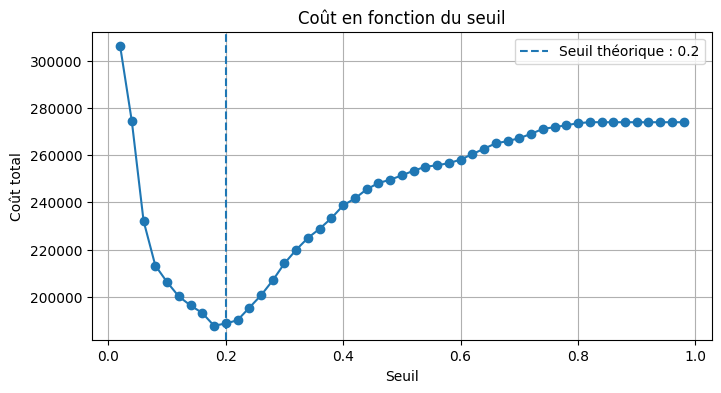

Seuil au coût minimal : 0.18
Coût minimal : 187775
Seuil théorique : 0.2
Différence entre les deux : 0.02
Coût au seuil 0,50 : 251425

Comparaison :
L'exactitude à 0,50 est de 82.32 %, contre 63.70 % au seuil 0.18. Le coût passe de 251425 à 187775, soit un gain de 63650 unités.

Tableau de calibration :


,proba_moyenne,taux_reel,effectif
tranche,,,
"(-0.001, 0.1]",0.052,0.053,5461
"(0.1, 0.2]",0.155,0.160,3546
"(0.2, 0.3]",0.245,0.256,3607
"(0.3, 0.5]",0.365,0.355,1925
"(0.5, 1.0]",0.627,0.599,451


  ok        un seuil écrit entre 0 et 1
  ok        deux coûts, des entiers positifs
  ok        l’écart est argumenté


In [29]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Vérifier les données
y_p = pd.Series(yval_perso)
probas = np.asarray(proba_perso)

if len(y_p) != len(probas):
    raise ValueError("Les probabilités et les vraies étiquettes doivent avoir la même longueur.")

# 1) Calculer le coût pour chaque seuil
seuils = np.round(np.arange(0.02, 1.0, 0.02), 2)
couts = []

for s in seuils:
    decision = pd.Series(
        (probas > s).astype(int),
        index=y_p.index
    )
    couts.append(cout(decision, verite=y_p))

# Afficher la courbe
plt.figure(figsize=(8, 4))
plt.plot(seuils, couts, marker="o")
plt.axvline(
    seuil_theorique,
    linestyle="--",
    label=f"Seuil théorique : {seuil_theorique}"
)
plt.xlabel("Seuil")
plt.ylabel("Coût total")
plt.title("Coût en fonction du seuil")
plt.legend()
plt.grid(True)
plt.show()

# 2) Trouver le seuil qui minimise le coût
i_min = int(np.argmin(couts))
mon_seuil_choisi = float(seuils[i_min])
cout_a_mon_seuil = int(couts[i_min])

print("Seuil au coût minimal :", mon_seuil_choisi)
print("Coût minimal :", cout_a_mon_seuil)
print("Seuil théorique :", seuil_theorique)

print(
    "Différence entre les deux :",
    round(abs(mon_seuil_choisi - seuil_theorique), 2)
)

# 3) Calculer le coût au seuil par défaut de 0,50
decision_defaut = pd.Series(
    (probas > 0.5).astype(int),
    index=y_p.index
)

cout_du_seuil_par_defaut = int(
    cout(decision_defaut, verite=y_p)
)

print("Coût au seuil 0,50 :", cout_du_seuil_par_defaut)

# 4) Comparer l'exactitude et le coût
exact_defaut = 100 * (decision_defaut == y_p).mean()

decision_choisie = pd.Series(
    (probas > mon_seuil_choisi).astype(int),
    index=y_p.index
)

exact_choisi = 100 * (decision_choisie == y_p).mean()

gain = cout_du_seuil_par_defaut - cout_a_mon_seuil

if cout_du_seuil_par_defaut != 0:
    part = 100 * gain / cout_du_seuil_par_defaut
else:
    part = 0.0

ecart_metrique_cout = (
    f"L'exactitude à 0,50 est de {exact_defaut:.2f} %, "
    f"contre {exact_choisi:.2f} % au seuil {mon_seuil_choisi}. "
    f"Le coût passe de {cout_du_seuil_par_defaut} "
    f"à {cout_a_mon_seuil}, soit un gain de {gain} unités."
)

print("\nComparaison :")
print(ecart_metrique_cout)

# 5) Examiner la calibration des probabilités
tranches = pd.cut(
    probas,
    bins=[0, 0.1, 0.2, 0.3, 0.5, 1.0],
    include_lowest=True
)

calib = pd.DataFrame({
    "proba": probas,
    "absent": y_p.to_numpy(),
    "tranche": tranches
})

calib = calib.groupby("tranche", observed=True).agg(
    proba_moyenne=("proba", "mean"),
    taux_reel=("absent", "mean"),
    effectif=("absent", "size")
)

print("\nTableau de calibration :")
display(calib.round(3))

controle('un seuil écrit entre 0 et 1', lambda: 0 < mon_seuil_choisi < 1, 'un seuil entre 0 et 1')
controle('deux coûts, des entiers positifs',
         lambda: cout_a_mon_seuil >= 0 and cout_du_seuil_par_defaut >= 0
                 and int(cout_a_mon_seuil) == cout_a_mon_seuil,
         'le coût est un entier, en unités de coût')
controle('l’écart est argumenté', lambda: len(ecart_metrique_cout) > 40,
         'chiffrez l’écart, et nommez les deux métriques comparées')


### Question 12 — Les deux classements  ·  *carnet J4*  ·  *cœur*


**Contexte.** Le classement affiché se fait sur l'**exactitude** ; le cours vient de montrer que la décision
se paie en **coût**. Les deux classements ne désignent donc pas la même tête.

**Consigne.**
  1. prenez **deux stratégies** au moins sur votre échantillon (par exemple *n'alerte jamais*, et le
     modèle à deux seuils différents) ;
  2. classez-les deux fois, du meilleur au moins bon : par **exactitude**, puis par **coût** ;
  3. dites si la tête change, et ce que cela coûte de se fier à la métrique affichée.

**Livrables.** `classement_exactitude` · `classement_cout` · `tete_change`.

**Critère de réussite.** Deux stratégies suffisent : ce qui compte est que les deux classements
soient **mesurés sur la même population**.

*≈ 15 min.*


In [30]:


import pandas as pd
import numpy as np

y_p = pd.Series(yval_perso)

probas = np.asarray(proba_perso)

# Trois stratégies évaluées sur le même échantillon
strategies = {
    "N'alerte jamais": pd.Series(
        0, index=y_p.index
    ),

    "Modèle à 0,50": pd.Series(
        (probas > 0.50).astype(int),
        index=y_p.index
    ),

    f"Modèle à {mon_seuil_choisi}": pd.Series(
        (probas > mon_seuil_choisi).astype(int),
        index=y_p.index
    )
}

# Calculer l'exactitude et le coût de chaque stratégie
lignes = []

for nom, decision in strategies.items():
    lignes.append({
        "stratégie": nom,
        "exactitude (%)": round(
            100 * (decision == y_p).mean(), 2
        ),
        "coût": int(cout(decision, verite=y_p))
    })

tab12 = pd.DataFrame(lignes)

print("Comparaison des stratégies :")
display(tab12)

# Classement par exactitude
classement_exactitude = (
    tab12.sort_values(
        "exactitude (%)",
        ascending=False
    )["stratégie"].tolist()
)

# Classement par coût
classement_cout = (
    tab12.sort_values(
        "coût",
        ascending=True
    )["stratégie"].tolist()
)

print("Classement par exactitude :", classement_exactitude)
print("Classement par coût :", classement_cout)

# Comparer les deux premières places
tete_exact = classement_exactitude[0]
tete_cout = classement_cout[0]

cout_tete_exact = int(
    tab12.loc[
        tab12["stratégie"] == tete_exact, "coût"
    ].iloc[0]
)

cout_tete_cout = int(
    tab12.loc[
        tab12["stratégie"] == tete_cout, "coût"
    ].iloc[0]
)

surcout = cout_tete_exact - cout_tete_cout

if tete_exact != tete_cout:
    tete_change = (
        f"Oui, les classements diffèrent. Par exactitude, "
        f"la meilleure stratégie est « {tete_exact} », "
        f"avec un coût de {cout_tete_exact}. "
        f"Par coût, la meilleure est « {tete_cout} », "
        f"avec un coût de {cout_tete_cout}. "
        f"La différence de coût est de {surcout} unités."
    )
else:
    tete_change = (
        f"Non, les deux classements ont le même premier : "
        f"« {tete_exact} ». Son coût est de {cout_tete_cout} unités."
    )

print("\nConclusion :")
print(tete_change)

controle('deux classements', lambda: len(classement_exactitude) >= 2 and len(classement_cout) >= 2,
         'deux stratégies au moins, classées deux fois')
controle('la réponse est argumentée', lambda: len(str(tete_change)) > 40,
         'dites si la tête change, et pourquoi')


Comparaison des stratégies :


,stratégie,exactitude (%),coût
0,N'alerte jamais,81.73,273900
1,"Modèle à 0,50",82.32,251425
2,Modèle à 0.18,63.70,187775


Classement par exactitude : ['Modèle à 0,50', "N'alerte jamais", 'Modèle à 0.18']
Classement par coût : ['Modèle à 0.18', 'Modèle à 0,50', "N'alerte jamais"]

Conclusion :
Oui, les classements diffèrent. Par exactitude, la meilleure stratégie est « Modèle à 0,50 », avec un coût de 251425. Par coût, la meilleure est « Modèle à 0.18 », avec un coût de 187775. La différence de coût est de 63650 unités.
  ok        deux classements
  ok        la réponse est argumentée


## Ce qu’on rend, et pourquoi ce format

**Trois tableaux**, comme au devoir 1 :

- **le tableau à quatre colonnes** — modèle · validation · affiché · écart — et vos trois phrases ;
- **le journal de nettoyage** — une ligne par décision : la décision, le choix fait, l’effet mesuré ;
- **le tableau d’essais** — une ligne par changement, avec l’attendu (un signe et une raison) et le
  mesuré.

Les **constats chiffrés** et les **hypothèses de features** appartiennent au **devoir 1**. Les
questions d’ici portent sur les baselines, le nettoyage et la mesure. Les tableaux qui les
portent sont ceux-ci. **Vos métriques, vos aires et votre seuil** (Q10, Q11) se lisent dans les cellules qui
les produisent.

La cellule qui suit affiche **les trois tableaux** remplis automatiquement, tels que vous les rendez.


In [31]:
print("vos essais \n")
display(pd.DataFrame(ESSAIS))
print("votre journal de nettoyage \n")
display(pd.DataFrame(JOURNAL))
print("votre tableau à quatre colonnes \n")
try:
    tableau_quatre_colonnes = mon_tableau
except NameError:
    tableau_quatre_colonnes = pd.DataFrame()
display(tableau_quatre_colonnes)
print("vos contrôles \n")
display(pd.DataFrame(VERIFICATIONS))


vos essais 



""


votre journal de nettoyage 



,décision,choix,raison (sans le score),effet mesuré,> double de la barre ?
0,colonnes inutiles,"Écartées : zone_clinique, indice_meteo_jour, s...",Ces colonnes n'apportent aucune information pr...,0.17,non
1,doublons,"0 doublon(s) détecté(s), aucune ligne retirée",Une ligne en double compterait deux fois le mê...,0.00,non
2,valeurs impossibles,46 âge(s) négatif(s) remplacé(s) par une valeu...,Un âge de -1 est impossible : c'est une valeur...,0.15,non
3,codes non documentés,code_assurance traité comme catégorie,Les codes de 1 à 9 sont des étiquettes sans or...,0.11,non


votre tableau à quatre colonnes 



,modèle,validation,affiché,écart
0,modèle du cours (boosting),82.34,81.81,-0.53
1,régression logistique,82.21,NaN,NaN
2,forêt aléatoire,81.84,NaN,NaN


vos contrôles 



,contrôle,tient
0,les données sont chargées,True
1,la table de travail est construite,True
2,"le découpage est fait, le modèle ajusté",True
3,les baselines sont mesurées,True
4,votre échantillon personnel est prêt,True
5,le pipeline tourne sur une table brute,True
6,le fichier est écrit,True
7,la règle est écrite,True
8,une exactitude en pourcentage,True
9,un écart exprimé en erreurs-types,True


## Rendre le travail

1. **Exécutez tout** le carnet (`Run All`), pour que les tableaux soient remplis.
2. **Déposez** ce carnet dans votre dépôt GitHub personnel. Mettez **avec** lui votre déclaration d’usage de
   l’IA, dans le **même commit** :
   - téléchargez le modèle **`DECLARATION_modele.md`** depuis le **dépôt du cours** ;
   - recopiez-le dans votre dépôt sous le nom **`declaration_DM2.md`** ;
   - remplissez-le : les deux scores, ce que vous avez produit seul, ce que vous avez fait
     avec un assistant, et ce que vous ne sauriez pas expliquer.
3. Vérifiez que le lien de votre dépôt est bien à jour dans le formulaire de la classe.

> Un travail non déposé n’existe pas.
